# DTD: texture category analysis

This analysis examines the image index and category table derived from the Voxel51 distribution of DTD. The recorded source revision is provided in `datasets/dtd/source.json`. The objectives are to verify index consistency and describe texture-category balance.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

candidates = [Path.cwd(), *Path.cwd().parents]
ROOT = next((p for p in candidates if (p / "datasets/dtd/source.json").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Open this notebook inside a cloned Fitwell-AI repository")
plt.rcParams.update({"figure.facecolor": "#f5f1ea", "axes.facecolor": "#f5f1ea", "font.size": 11})
print("Repository:", ROOT.name)


Repository: repo


In [2]:
images = pd.read_csv(ROOT / "datasets/dtd/images.csv")
categories = pd.read_csv(ROOT / "datasets/dtd/categories.csv")
assert len(images) == 5640 and images["relative_path"].is_unique
counts = images.groupby("texture_label").size().rename("images").sort_index()
assert len(counts) == 47
assert counts.eq(120).all()
assert counts.to_dict() == categories.set_index("texture_label")["image_count"].to_dict()
print(f"Images: {len(images):,}; texture categories: {len(counts)}; duplicate paths: {images.relative_path.duplicated().sum()}")
print(counts.to_string())

Images: 5,640; texture categories: 47; duplicate paths: 0
texture_label
banded          120
blotchy         120
braided         120
bubbly          120
bumpy           120
chequered       120
cobwebbed       120
cracked         120
crosshatched    120
crystalline     120
dotted          120
fibrous         120
flecked         120
freckled        120
frilly          120
gauzy           120
grid            120
grooved         120
honeycombed     120
interlaced      120
knitted         120
lacelike        120
lined           120
marbled         120
matted          120
meshed          120
paisley         120
perforated      120
pitted          120
pleated         120
polka-dotted    120
porous          120
potholed        120
scaly           120
smeared         120
spiralled       120
sprinkled       120
stained         120
stratified      120
striped         120
studded         120
swirly          120
veined          120
waffled         120
woven           120
wrinkled        120
zigzagge

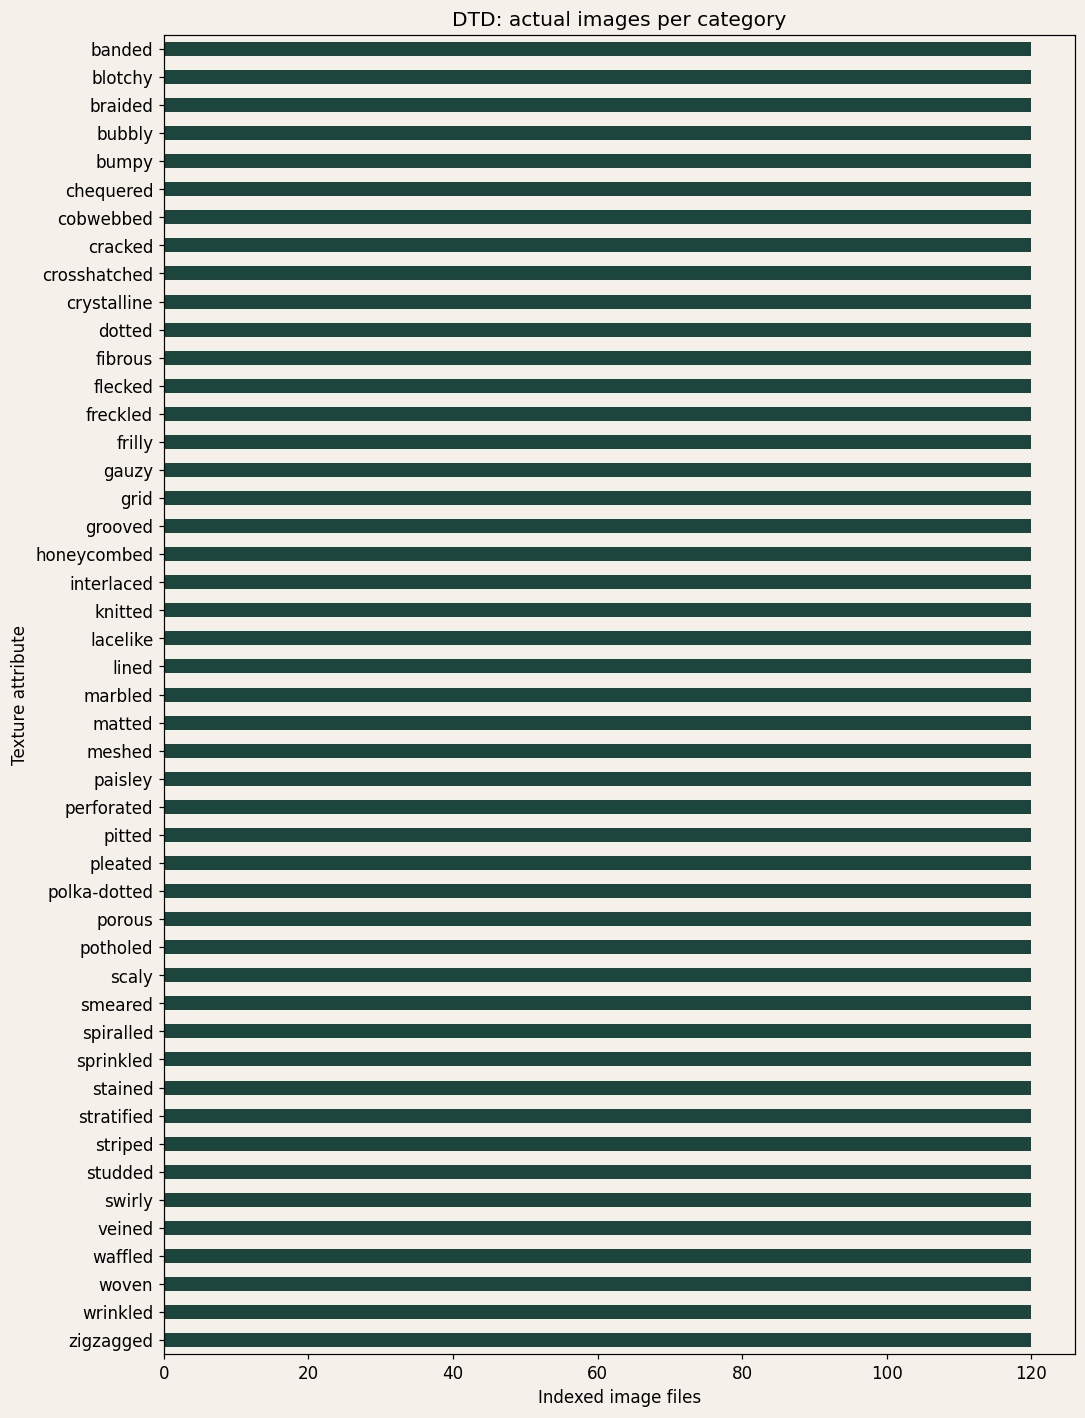

In [3]:
fig, ax = plt.subplots(figsize=(10, 13))
counts.sort_index(ascending=False).plot.barh(ax=ax, color="#1c463d")
ax.set_xlabel("Indexed image files")
ax.set_ylabel("Texture attribute")
ax.set_title("DTD: actual images per category")
plt.tight_layout()
plt.show()

## Interpretation

The indexed collection contains 47 categories with 120 images per category. Evaluation partitions are not assigned by this index; subsequent experiments require the original DTD protocols or a documented alternative. The complete archive is available through GitHub Releases. These descriptive counts do not provide evidence of model recognition accuracy.